In [1]:
import pandas as pd
from pathlib import Path

import load_data

In [ ]:
hl_hype = load_data.get_md(
    'HYPERLIQUID',
    'HYPE-USD-PERP',
    'book')
    
bin_hype = load_data.get_md(
    'BINANCE_FUTURES',
    'HYPE-USDT-PERP',
    'book')

In [ ]:
hl_hype.head()

In [4]:
b_1min = (
    bin_hype[["mid", "bid", 'ask', 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("60000ms")
    .last()
    .ffill()
    .rename(columns={"mid": "bin_mid", "bid": "bin_bid", 
                    'bid_size':'bid_size_bin', 'ask_size':'ask_size_bin',
                    'imbalance':'imbalance_bin', 'microprice':'microprice_bin'})
)

h_1min = (
    hl_hype[["mid", "bid", 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("60000ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hl_mid", "bid": "hl_bid",
                    'bid_size':'bid_size_hl', 'ask_size':'ask_size_hl',
                    'imbalance':'imbalance_hl', 'microprice':'microprice_hl'})
)

# Merge them on their timestamp indexes
df = b_1min.join(h_1min, how="inner")
df.tail()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl
datetime,,,,,,,,,,,,,
2026-10-02 10:55:00+00:00,90.9295,90.929,90.930,67.18,10.44,0.730997,90.929865,91.0205,91.020,407.79,170.29,0.410843,91.020705
2026-10-02 10:56:00+00:00,90.9565,90.956,90.957,30.54,51.43,-0.254849,90.956373,91.0335,91.033,78.19,356.25,-0.640042,91.033180
2026-10-02 10:57:00+00:00,90.9175,90.917,90.918,100.94,51.68,0.322762,90.917661,90.9935,90.986,4.40,383.23,-0.977298,90.986170
2026-10-02 10:58:00+00:00,90.8955,90.895,90.896,102.52,68.26,0.200609,90.895600,90.9745,90.974,123.79,22.42,0.693318,90.974847
2026-10-02 10:59:00+00:00,90.8775,90.877,90.878,23.81,218.01,-0.803077,90.877098,90.9835,90.983,6.26,27.22,-0.626045,90.983187


In [5]:
df['microprice_diff'] = df['microprice_hl'] - df['microprice_bin']
df["mid_diff"] = (
    df["hl_mid"]
    - df["bin_mid"]
)

df["reference_mid"] = (
    df["hl_mid"]
    + df["bin_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hl_mid"]
    - df["bin_mid"]
) / df["reference_mid"] * 10_000

In [6]:
df.head()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl,microprice_diff,mid_diff,reference_mid,mid_diff_bps
datetime,,,,,,,,,,,,,,,,,
2026-09-29 03:16:00+00:00,86.2415,86.241,86.242,62.57,44.03,0.173921,86.241587,86.2475,86.247,2.25,175.92,-0.974743,86.247013,0.005426,0.0060,86.24450,0.695697
2026-09-29 03:17:00+00:00,86.3175,86.317,86.318,32.95,73.79,-0.382612,86.317309,86.3430,86.338,3.05,4.63,-0.205729,86.341971,0.024663,0.0255,86.33025,2.953773
2026-09-29 03:18:00+00:00,86.3035,86.303,86.304,141.78,1.01,0.985853,86.303993,86.2965,86.296,146.59,107.44,0.154116,86.296577,-0.007416,-0.0070,86.30000,-0.811124
2026-09-29 03:19:00+00:00,86.4245,86.424,86.425,33.54,25.10,0.143929,86.424572,86.4625,86.462,0.13,722.38,-0.999640,86.462000,0.037428,0.0380,86.44350,4.395935
2026-09-29 03:20:00+00:00,86.5165,86.516,86.517,30.00,41.20,-0.157303,86.516421,86.5175,86.517,243.10,494.08,-0.340460,86.517330,0.000908,0.0010,86.51700,0.115584


In [11]:
spread_bps[-200:]

datetime
2026-10-02 07:40:00+00:00     0.445566
2026-10-02 07:41:00+00:00    -0.111298
2026-10-02 07:42:00+00:00     0.778678
2026-10-02 07:43:00+00:00     0.667278
2026-10-02 07:44:00+00:00     3.283058
                               ...    
2026-10-02 10:55:00+00:00    10.002748
2026-10-02 10:56:00+00:00     8.462003
2026-10-02 10:57:00+00:00     8.355734
2026-10-02 10:58:00+00:00     8.687524
2026-10-02 10:59:00+00:00    11.657255
Freq: 60000ms, Length: 200, dtype: float64

Hyperliquid PENDLE-USD (tier 6): fees                        0.24
Hyperliquid PENDLE-USD (tier 6): half-spread (taker legs)    0.18
Binance PENDLE-USDT (VIP 0): fees                            4.30
Binance PENDLE-USDT (VIP 0): half-spread (taker legs)        0.20
TOTAL round-trip cost                                        4.92

break-even move  : 4.92 bps  (= 49 USD per 100,000 notional)
deviation |x| >= cost : 16.4% of bars
best TP in grid  : 15 bps  EV +6.75 bps  hit 77%


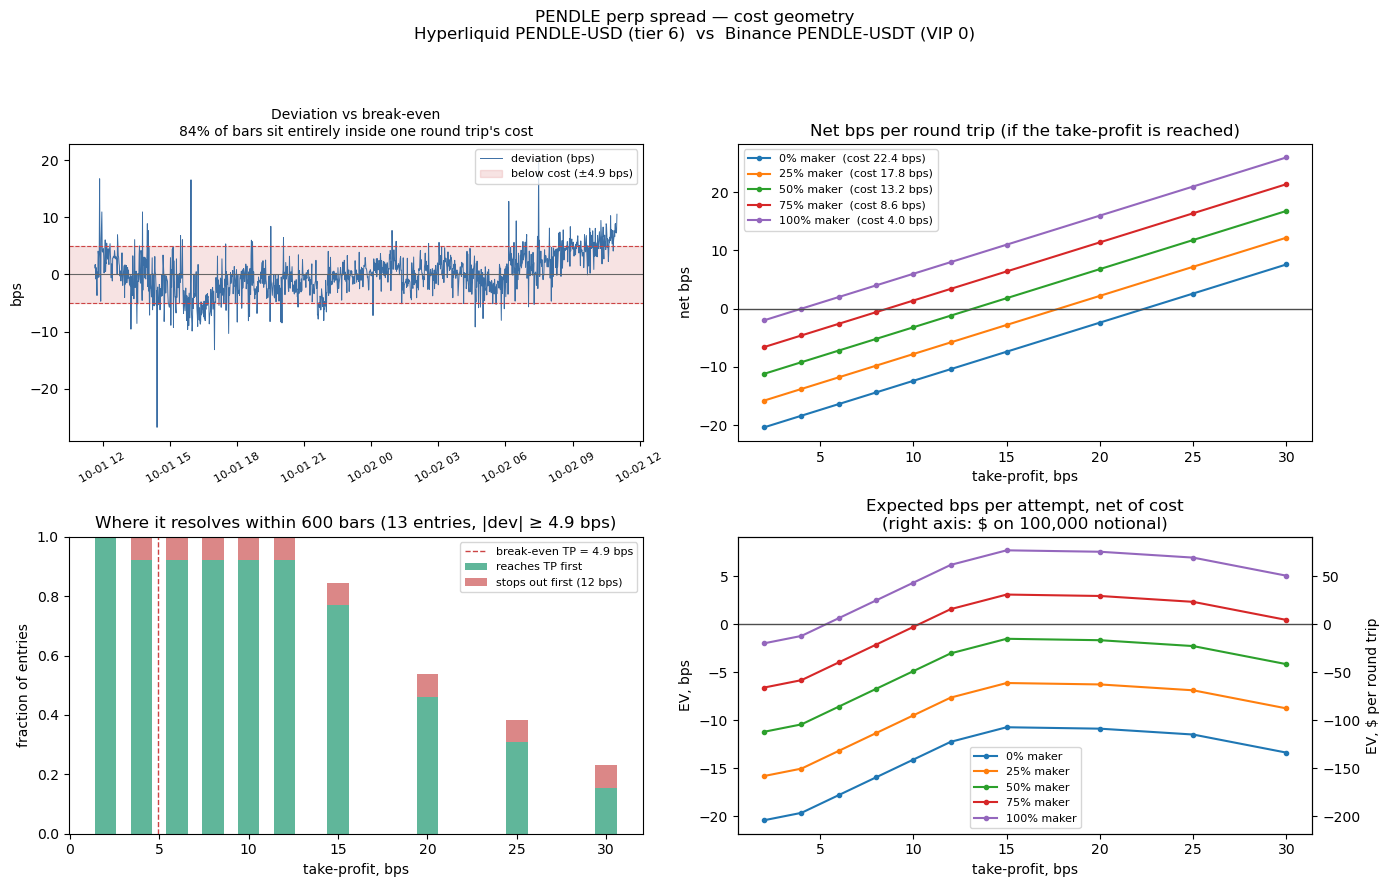

In [12]:
from spread_cost import plot_pnl, cost_breakdown

ref        = (df.hl_mid + df.bin_mid) / 2
spread_bps = (df.hl_mid - df.bin_mid) / ref * 1e4

fig, res = plot_pnl(spread_bps[-2_000:], taker=0.05, maker=0.95,
                    stop_bps=12, horizon_bars=600)   # 600 bars = 60s at 100ms

## Markov-Switching Latent Fair-Value Model

Start with the observed price decomposition:

$$
p_t = m_t + s_t + \epsilon_t
$$

where:

- $p_t$ = observed market price
- $m_t$ = latent efficient / fair price
- $s_t$ = temporary, predictable microstructure distortion
- $\epsilon_t$ = residual observation noise

### Efficient-price process

Model the latent efficient price as a random walk:

$$
m_t = m_{t-1} + \eta_t
$$

where $\eta_t$ represents innovations to the true efficient price.

### Microstructure distortion

Let the temporary distortion depend on both its previous value and current market-microstructure information:

$$
s_t
=
\rho_{z_t}s_{t-1}
+
\beta_{z_t}^{\top}x_t
+
\nu_t
$$

where:

- $z_t$ = latent market regime
- $\rho_{z_t}$ = persistence of temporary price distortion in regime $z_t$
- $\beta_{z_t}$ = regime-dependent weights on market-microstructure variables
- $x_t$ = vector of observable order-book / order-flow features
- $\nu_t$ = innovation to the temporary distortion

A simple initial feature vector could be:

$$
x_t =
\begin{bmatrix}
\text{microprice} - \text{midprice} \\
\text{order-flow imbalance} \\
\text{trade imbalance} \\
\text{bid-ask spread} \\
\text{depth imbalance}
\end{bmatrix}
$$

### Markov regime process

Assume the latent regime follows a Markov process:

$$
z_t \sim \operatorname{Markov}(P)
$$

where:

$$
P_{ij}
=
P(z_t = j \mid z_{t-1} = i)
$$

Possible regimes may correspond to states such as:

1. Balanced / normal market
2. Sustained buy pressure
3. Sustained sell pressure
4. Low-liquidity / stressed market

The regimes do not necessarily need to be manually labelled beforehand; they can be inferred statistically and interpreted afterwards.

### Fair-value estimate

The model produces an estimate of the current temporary distortion:

$$
\hat{s}_t
=
E[s_t \mid \mathcal{F}_t]
$$

and therefore the estimated latent efficient price is:

$$
\boxed{
\hat{m}_t = p_t - \hat{s}_t
}
$$

The purpose of the model is therefore to use observable microstructure information to separate temporary price pressure from movements in the underlying efficient price.

### Research progression

A natural progression for the research is:

1. **Midprice benchmark**
2. **Microprice benchmark**
3. **Linear microstructure fair-value model**
4. **Regime-dependent / Markov model**
5. **Full Markov-switching state-space model**

Each increase in complexity should only be retained if it improves out-of-sample estimates of the latent fair price or subsequent price movement.